# Online Retail: Who Are the Most Valuable Customers?

**Business question:** A UK online gift shop wants to know which customers bring in the most money, which customers it is losing, and how sales change through the year.

**Data:** One year of real transactions (1 Dec 2010 to 9 Dec 2011) from the UCI Machine Learning Repository. Each row is one product on one invoice.

**Tools:** Python (pandas, matplotlib) for cleaning and charts, SQL (SQLite) for the analysis.

**Steps:**
1. Load and look at the data
2. Clean it
3. Answer business questions with SQL
4. Group customers using RFM
5. Findings and recommendations

## 1. Load and look at the data

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/online_retail.csv.gz",
                 dtype={"InvoiceNo": str, "StockCode": str, "CustomerID": str})
print("Rows and columns:", df.shape)
df.head()

Rows and columns: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850,United Kingdom


In [2]:
# How many values are missing in each column?
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

About a quarter of the rows have no `CustomerID`. Those sales cannot be linked to a customer, so they cannot be used in a customer analysis.

## 2. Clean the data

Cleaning rules, each one explained:
1. **Remove exact duplicate rows**: the same line entered twice.
2. **Remove rows with no customer ID**: we cannot analyse a customer we cannot identify.
3. **Remove cancelled orders**: invoice numbers starting with `C` are cancellations. If a customer cancelled the exact same product and quantity they ordered, the original order line is removed too. Otherwise a huge order that was cancelled the same day would still count as a sale.
4. **Remove zero or negative quantities and prices**: these are errors or adjustments.
5. **Remove non-product lines**: postage, bank charges and manual adjustments are not products.

In [3]:
print("Rows at start:", len(df))

df = df.drop_duplicates()
print("After removing duplicates:", len(df))

df = df[df["CustomerID"].notna()]
print("After removing rows with no customer:", len(df))

# Find the cancellations, and the original orders they cancel
is_cancel = df["InvoiceNo"].str.startswith("C")
cancel_keys = (df.loc[is_cancel, "CustomerID"] + "|" + df.loc[is_cancel, "StockCode"]
               + "|" + df.loc[is_cancel, "Quantity"].abs().astype(str))
order_keys = df["CustomerID"] + "|" + df["StockCode"] + "|" + df["Quantity"].astype(str)
was_cancelled = ~is_cancel & order_keys.isin(cancel_keys)

df = df[~is_cancel & ~was_cancelled]
print("After removing cancellations and the orders they cancelled:", len(df))

df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
print("After removing zero or negative values:", len(df))

non_products = ["POST", "DOT", "M", "C2", "BANK CHARGES", "AMAZONFEE", "PADS", "D", "S", "B", "CRUK"]
df = df[~df["StockCode"].isin(non_products)]
print("After removing postage and fees:", len(df))

Rows at start: 541909


After removing duplicates: 536641
After removing rows with no customer: 401604


After removing cancellations and the orders they cancelled: 387255
After removing zero or negative values: 387220
After removing postage and fees: 385929


In [4]:
# Dates in this file are written month-first, e.g. 12/1/2010 = 1 December 2010
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], format="%m/%d/%Y %H:%M")

# Revenue for each line = quantity x price
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

print("Data runs from", df["InvoiceDate"].min().date(), "to", df["InvoiceDate"].max().date())
df.head()

Data runs from 2010-12-01 to 2011-12-09


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


## 3. Answer business questions with SQL

The clean data is loaded into a small SQLite database, so the questions can be answered with SQL. Each query is also saved in the `sql/` folder.

In [5]:
sales = df.rename(columns={
    "InvoiceNo": "invoice_no", "StockCode": "stock_code", "Description": "description",
    "Quantity": "quantity", "InvoiceDate": "invoice_date", "UnitPrice": "unit_price",
    "CustomerID": "customer_id", "Country": "country", "Revenue": "revenue"})
sales["invoice_date"] = sales["invoice_date"].dt.strftime("%Y-%m-%d %H:%M:%S")

conn = sqlite3.connect(":memory:")
sales.to_sql("sales", conn, index=False)

def run_sql(file_name):
    query = open(f"sql/{file_name}.sql").read()
    return pd.read_sql(query, conn)

### How big is the business?

In [6]:
run_sql("01_overview")

,orders,customers,total_revenue
0,18162,4321,8199424.0


### How does revenue change month by month?
`LAG()` puts the previous month's revenue on the same row, so growth is a simple calculation.

In [7]:
monthly = run_sql("02_monthly_revenue")
monthly

,month,revenue,previous_month,growth_pct
0,2010-12,551592.0,NaN,NaN
1,2011-01,453016.0,551592.0,-17.9
2,2011-02,435946.0,453016.0,-3.8
3,2011-03,565995.0,435946.0,29.8
4,2011-04,427055.0,565995.0,-24.5
5,2011-05,647181.0,427055.0,51.5
6,2011-06,600076.0,647181.0,-7.3
7,2011-07,577445.0,600076.0,-3.8
8,2011-08,620151.0,577445.0,7.4
9,2011-09,921786.0,620151.0,48.6


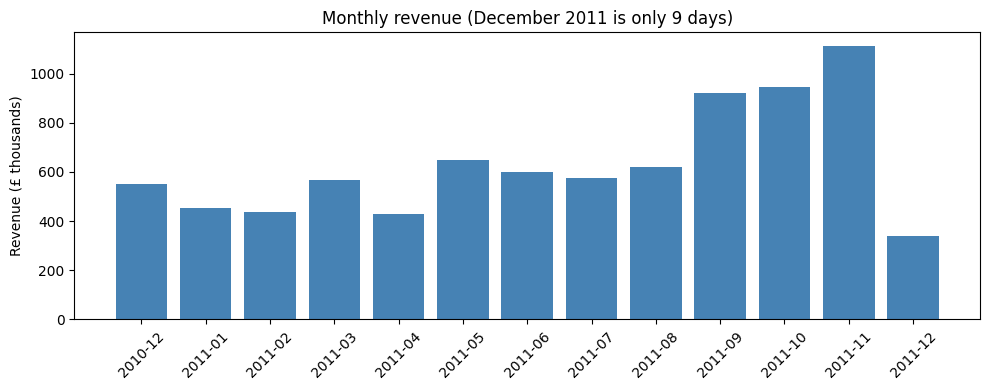

In [8]:
plt.figure(figsize=(10, 4))
plt.bar(monthly["month"], monthly["revenue"] / 1000, color="steelblue")
plt.title("Monthly revenue (December 2011 is only 9 days)")
plt.ylabel("Revenue (£ thousands)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("images/monthly_revenue.png", dpi=120)
plt.show()

### Which countries bring the most revenue?

In [9]:
countries = run_sql("03_top_countries")
uk_share = countries.loc[countries["country"] == "United Kingdom", "revenue"].iloc[0] / sales["revenue"].sum() * 100
print(f"The UK brings {uk_share:.1f}% of all revenue")
countries

The UK brings 82.2% of all revenue


,country,customers,revenue
0,United Kingdom,3906,6743498.0
1,Netherlands,9,282162.0
2,EIRE,3,236942.0
3,Germany,94,203090.0
4,France,87,180845.0
5,Australia,9,136920.0
6,Spain,29,51929.0
7,Switzerland,21,51859.0
8,Japan,8,37212.0
9,Belgium,25,36814.0


### Which products sell the most?

In [10]:
run_sql("04_top_products")

,description,units_sold,revenue
0,REGENCY CAKESTAND 3 TIER,11683,134365.0
1,WHITE HANGING HEART T-LIGHT HOLDER,32067,88741.0
2,JUMBO BAG RED RETROSPOT,43005,79650.0
3,PARTY BUNTING,14937,67293.0
4,ASSORTED COLOUR BIRD ORNAMENT,35197,56301.0
5,RABBIT NIGHT LIGHT,27087,51114.0
6,CHILLI LIGHTS,9549,45815.0
7,PAPER CHAIN KIT 50'S CHRISTMAS,14743,40419.0
8,BLACK RECORD COVER FRAME,11377,38956.0
9,SPOTTY BUNTING,7629,35490.0


### How many customers come back?

In [11]:
repeat = run_sql("06_repeat_customers")
repeat

,customer_type,customers,pct_of_customers
0,One-time buyer,1506,34.9
1,Repeat buyer,2815,65.1


## 4. Group customers using RFM

RFM is a common way to rank customers:
- **Recency**: how many days since their last order (recent is better)
- **Frequency**: how many orders they placed (more is better)
- **Monetary**: how much they spent (more is better)

`NTILE(5)` splits customers into five equal groups and gives each a score from 1 to 5. Then four simple groups are made:

| Group | Rule | Meaning |
|---|---|---|
| Champions | Recent and frequent | Best customers, keep them happy |
| At risk | Used to buy often, not recently | Win them back before they leave |
| Active | Bought recently | Grow them into Champions |
| Lost | Not recent, not frequent | Low priority |

In [12]:
rfm = run_sql("05_rfm_segments")
rfm.head()

,customer_id,recency_days,frequency,monetary,r_score,f_score,m_score,segment
0,13747,373,1,79.60,1,1,1,Lost
1,17643,373,1,101.55,1,1,1,Lost
2,18011,373,1,102.79,1,1,1,Lost
3,15350,373,1,115.65,1,1,1,Lost
4,14237,373,1,161.00,1,1,1,Lost


In [13]:
summary = rfm.groupby("segment").agg(
    customers=("customer_id", "count"),
    revenue=("monetary", "sum"),
    avg_orders=("frequency", "mean"),
    avg_days_since_last_order=("recency_days", "mean"),
).round(1)
summary["pct_customers"] = (summary["customers"] / summary["customers"].sum() * 100).round(1)
summary["pct_revenue"] = (summary["revenue"] / summary["revenue"].sum() * 100).round(1)
summary = summary.sort_values("revenue", ascending=False)
summary

,customers,revenue,avg_orders,avg_days_since_last_order,pct_customers,pct_revenue
segment,,,,,,
Champions,1123,5697098.7,9.9,12.6,26.0,69.5
Active,1469,1350835.9,2.5,36.5,34.0,16.5
At risk,648,776075.0,3.4,148.8,15.0,9.5
Lost,1081,375414.3,1.1,218.1,25.0,4.6


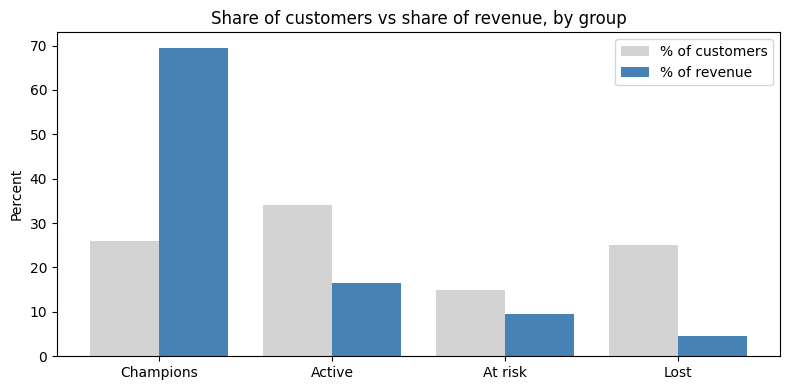

In [14]:
fig, ax = plt.subplots(figsize=(8, 4))
x = range(len(summary))
ax.bar([i - 0.2 for i in x], summary["pct_customers"], width=0.4, label="% of customers", color="lightgray")
ax.bar([i + 0.2 for i in x], summary["pct_revenue"], width=0.4, label="% of revenue", color="steelblue")
ax.set_xticks(list(x))
ax.set_xticklabels(summary.index)
ax.set_ylabel("Percent")
ax.set_title("Share of customers vs share of revenue, by group")
ax.legend()
plt.tight_layout()
plt.savefig("images/segments.png", dpi=120)
plt.show()

### Do a few customers bring most of the money?

In [15]:
spend = rfm["monetary"].sort_values(ascending=False)
top_20_pct = spend.head(int(len(spend) * 0.2))
share = top_20_pct.sum() / spend.sum() * 100
print(f"The top 20% of customers bring {share:.1f}% of revenue")

The top 20% of customers bring 73.4% of revenue


## 5. Findings and recommendations

In [16]:
champ = summary.loc["Champions"]
risk = summary.loc["At risk"]
one_time = repeat.loc[repeat["customer_type"] == "One-time buyer", "pct_of_customers"].iloc[0]
print(f"1. Champions are {champ.pct_customers}% of customers but bring {champ.pct_revenue}% of revenue.")
print(f"2. {int(risk.customers)} customers are 'At risk': they used to order often but have not ordered for about {risk.avg_days_since_last_order:.0f} days on average.")
print(f"3. {one_time}% of customers ordered only once and never came back.")
print(f"4. The top 20% of customers bring {share:.1f}% of revenue.")
print(f"5. Sales peak in October and November, before Christmas.")

1. Champions are 26.0% of customers but bring 69.5% of revenue.
2. 648 customers are 'At risk': they used to order often but have not ordered for about 149 days on average.
3. 34.9% of customers ordered only once and never came back.
4. The top 20% of customers bring 73.4% of revenue.
5. Sales peak in October and November, before Christmas.


**Recommendations**
1. **Protect the Champions**: a loyalty programme or early access to new products, because losing a few of them costs a lot.
2. **Win back the At-risk group**: a personal offer to customers who used to buy often but have gone quiet.
3. **Turn first orders into second orders**: a follow-up offer after the first purchase, because many customers never return.
4. **Plan stock for the autumn peak**: most revenue arrives in October and November.

**Limitations**
- One shop, one year, mostly UK customers. The results describe this shop, not retail in general.
- The data has no product costs, so profit cannot be calculated.
- Sales without a customer ID (about a quarter of rows) are not in the customer analysis.
- December 2011 has only 9 days of data.